# Chapter 11: Repeated Games, Cooperation, and Enforcement

This notebook reruns four worked examples from the chapter: a pollution charge that ends a prisoners dilemma, the volunteer's dilemma of a storm drain, unraveling with a known last round against an uncertain end, and the punishment length that deters a capacity cut. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def payoff_matrix(ax, row_names, col_names, payoffs, highlight=None, row_player="Row", col_player="Column"):
    """2 x 2 (or n x m) payoff table drawn as a figure. ``payoffs[i][j] = (row, col)``.

    ``highlight`` is a set of (i, j) cells to shade (for example Nash equilibria).
    Axis labels name the players so the engine's axis-label check passes.
    """
    highlight = set(highlight or [])
    n, m = len(row_names), len(col_names)
    for i in range(n):
        for j in range(m):
            y = n - 1 - i
            face = PALETTE["light"] if (i, j) in highlight else "white"
            ax.add_patch(__import__("matplotlib").patches.Rectangle((j, y), 1, 1, fc=face, ec=PALETTE["ink"]))
            r, c = payoffs[i][j]
            ax.text(j + 0.5, y + 0.5, f"{r}, {c}", ha="center", va="center", fontsize=12, color=PALETTE["ink"])
    ax.set_xlim(0, m)
    ax.set_ylim(0, n)
    ax.set_xticks([j + 0.5 for j in range(m)], col_names)
    ax.set_yticks([n - 1 - i + 0.5 for i in range(n)], row_names)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(f"{col_player} chooses")
    ax.set_ylabel(f"{row_player} chooses")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def nash_2x2(payoffs, tol=1e-12):
    """Pure and interior mixed Nash equilibria of a 2 x 2 game.

    payoffs[i][j] = (row payoff, column payoff) when row plays i and column plays j.
    Returns {"pure": [(i, j), ...], "mixed": (p, q) or None, "mixed_payoffs": (row, col) or None}
    where p is the probability row plays 0 and q the probability column plays 0.
    Principle: nash-equilibrium-and-existence. Book (ch009): with (O,O) = (2,2), (O,N) = (6,0),
    (N,O) = (0,6), (N,N) = (4,4) the unique equilibrium is (O,O); with (O,O) = (-1,-1) the pure
    equilibria are (O,N) and (N,O) and the mixed one has p = q = 2/3 with payoff 4/3.
    """
    r = [[payoffs[i][j][0] for j in range(2)] for i in range(2)]
    c = [[payoffs[i][j][1] for j in range(2)] for i in range(2)]
    pure = [(i, j) for i in range(2) for j in range(2)
            if r[i][j] >= r[1 - i][j] - tol and c[i][j] >= c[i][1 - j] - tol]
    den_q = r[0][0] - r[0][1] - r[1][0] + r[1][1]
    den_p = c[0][0] - c[1][0] - c[0][1] + c[1][1]
    mixed = mixed_pay = None
    if abs(den_q) > tol and abs(den_p) > tol:
        q = (r[1][1] - r[0][1]) / den_q
        p = (c[1][1] - c[1][0]) / den_p
        if tol < p < 1 - tol and tol < q < 1 - tol:
            mixed = (p, q)
            mixed_pay = (q * r[0][0] + (1 - q) * r[0][1], p * c[0][0] + (1 - p) * c[1][0])
    return {"pure": pure, "mixed": mixed, "mixed_payoffs": mixed_pay}


def dominance_check(payoffs):
    """Dominance for each player of a 2 x 2 game (payoffs[i][j] = (row, column)).

    Returns {"row": (kind, action), "col": (kind, action)} where kind is "strict", "weak" or None
    and action is the dominant action index (None if no dominance).
    Principle: prisoners-dilemma. Book (ch011): T = 8 > R = 6 > P = 3 > S = 1 makes Dirty strictly
    dominant; with a charge f = 3, 6 > 5 and 1 > 0 make Filter strictly dominant.
    """
    def kind(a, b):
        if all(x > y for x, y in zip(a, b)):
            return "strict"
        if all(x >= y for x, y in zip(a, b)) and any(x > y for x, y in zip(a, b)):
            return "weak"
        return None
    rows = [[payoffs[i][j][0] for j in range(2)] for i in range(2)]
    cols = [[payoffs[i][j][1] for i in range(2)] for j in range(2)]
    out = {}
    for name, opts in (("row", rows), ("col", cols)):
        k0, k1 = kind(opts[0], opts[1]), kind(opts[1], opts[0])
        out[name] = (k0, 0) if k0 else ((k1, 1) if k1 else (None, None))
    return out


def grim_trigger_threshold(R, T, P):
    """Smallest discount factor sustaining grim-trigger cooperation: (T - R) / (T - P).

    Principle: one-shot-deviation-principle. Book (ch010): R = 8, T = 12, P = 5 gives 4/7 = 0.571.
    """
    return (T - R) / (T - P)


def repeated_values(delta, R, T, P, k=None):
    """Value of cooperating forever versus deviating once and then being punished.

    V_C = R / (1 - delta). With k=None (grim trigger) V_D = T + delta P / (1 - delta); with a finite
    punishment of k periods V_D = T + P (delta + ... + delta^k) + delta^(k+1) R / (1 - delta).
    Returns (V_C, V_D). Principle: one-shot-deviation-principle. Book (ch010): delta = 0.7, R = 8,
    T = 12, P = 5 gives 26.667 and 23.667; delta = 0.5 gives 16 and 17.
    """
    vc = R / (1 - delta)
    if k is None:
        vd = T + delta * P / (1 - delta)
    else:
        vd = T + P * sum(delta ** t for t in range(1, k + 1)) + delta ** (k + 1) * R / (1 - delta)
    return vc, vd


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(nash_2x2=nash_2x2, dominance_check=dominance_check, grim_trigger_threshold=grim_trigger_threshold, repeated_values=repeated_values)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'prisoners-dilemma': {'T': 8,
                       'R': 6,
                       'P': 3,
                       'S': 1,
                       'total_DD': 6,
                       'total_CC': 12,
                       'gain': 2,
                       'f': 3,
                       'dirty_vs_filter': 5,
                       'dirty_vs_dirty': 0},
 'volunteers-dilemma': {'n': 4,
                        'B': 120,
                        'C': 30,
                        'p': 0.37,
                        'fail': 0.157,
                        'provision_pct': 84.3,
                        'volunteers': 1.48,
                        'payoff': 90,
                        'C_reimbursed': 7.5,
                        'p_alt': 0.603,
                        'fail_alt': 0.025},
 'finite-horizon-unraveling': {'R': 4,
                               'T': 6,
                               'S': 0,
                               'P': 1,
                               'rounds': 3,
                               'total_shirk': 3,
                               'total_check': 12,
                               'q': 0.8,
                               'V_C': 20,
                               'V_D': 10},
 'trigger-strategy-enforcement-in-repeated-games': {'R': 6,
                                                    'T': 10,
                                                    'S': 0,
                                                    'P': 2,
                                                    'threshold': 0.5,
                                                    'delta': 0.75,
                                                    'V_C': 24,
                                                    'V_D_grim': 16,
                                                    'V_D_two': 22.75,
                                                    'V_D_one': 25,
                                                    'delta_low': 0.4,
                                                    'V_C_low': 10,
                                                    'V_D_low': 11.33},
 'constructed': {'prisoners-dilemma': {'f': [1, 2]},
                 'volunteers-dilemma': {'n': [2, 6], 'C': [60]},
                 'finite-horizon-unraveling': {'q': [0.3, 0.4]},
                 'trigger-strategy-enforcement-in-repeated-games': {'delta': [0.9]}}}


def sum_digits(terms, start=2):
    """Fewest decimals (from ``start``) at which the rounded terms add to the rounded total."""
    total = sum(terms)
    for d in range(start, 8):
        if round(sum(round(t, d) for t in terms), d) == round(total, d):
            return d
    return 8


def dilemma_picture(f=0):
    pay = [[(6, 6), (1, 8 - f)], [(8 - f, 1), (3 - f, 3 - f)]]
    res = games.nash_2x2(pay)
    dom = games.dominance_check(pay)["row"]
    names = ["Filter (C)", "Dirty (D)"]
    fig, ax = new_figure()
    payoff_matrix(ax, names, names, pay, highlight=res["pure"], row_player="North Mill", col_player="South Mill")
    eqs = join_and([f"({'CD'[i]}, {'CD'[j]})" for i, j in res["pure"]])
    if dom[0] == "strict":
        domtxt = f"{'Filter' if dom[1] == 0 else 'Dirty'} strictly dominates"
    elif dom[0] == "weak":
        domtxt = f"{'Filter' if dom[1] == 0 else 'Dirty'} weakly dominates"
    else:
        domtxt = "neither action dominates: each mill is indifferent against both rival actions"
    comp1 = f"Against a filtering rival: Filter 6, Dirty 8 - {f} = {8 - f}"
    comp2 = f"Against a dirty rival: Filter 1, Dirty 3 - {f} = {3 - f}"
    metrics = {"Dominance": domtxt, "Nash equilibria": eqs, "Total at (C, C)": "12",
               "Total at the equilibrium": (str(2 * (3 - f)) if res["pure"] == [(1, 1)] else
                                            "12" if res["pure"] == [(0, 0)] else f"from {2 * (3 - f)} to 12"),
               "Gain from defecting at (C, C)": num(8 - f - 6, 0)}
    if len(res["pure"]) == 4:
        tail = f"Every one of the four profiles is a Nash equilibrium; a charge above 2 is needed to make filtering strictly dominant."
    else:
        tail = f"The unique equilibrium is {eqs}."
    interp = f"{comp1}; {comp2}. So {domtxt}. {tail} Defecting from (C, C) gains 8 - {f} - 6 = {8 - f - 6}."
    steps = [comp1, comp2, f"Equilibria: {eqs}"]
    alt = f"Payoff matrix of two mills with a charge of {f} on dirty operation; equilibria {eqs}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def volunteers(n, B, C):
    """Symmetric mixed equilibrium of the volunteer's dilemma (principle: volunteers-dilemma).

    p* = 1 - (C/B)^(1/(n-1)); failure (1 - p*)^n. Book (ch011): n = 4, B = 120, C = 30 gives 0.370,
    0.157, 84.3 percent, 1.48 volunteers and payoff 90; C = 7.5 gives 0.603 and 0.025.
    """
    p = 1 - (C / B) ** (1 / (n - 1))
    fail = (1 - p) ** n
    return {"p": p, "fail": fail, "provision": 1 - fail, "volunteers": n * p, "payoff": B - C}


def volunteer_picture(n=4, cost=30):
    r = volunteers(n, 120, cost)
    fig, ax = new_figure()
    bars = ax.bar([0, 1, 2], [r["p"], r["fail"], r["provision"]], width=0.6,
                  color=[PALETTE["teal"], PALETTE["terracotta"], PALETTE["navy"]])
    for x, v in zip([0, 1, 2], [r["p"], r["fail"], r["provision"]]):
        ax.annotate(num(v, 3), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks([0, 1, 2], ["each merchant acts", "nobody acts", "drain cleared"])
    ax.set_ylim(0, 1.12)
    ax.set_xlabel(f"{n} merchants, cost {num(cost, 1)} against a benefit of 120")
    ax.set_ylabel("Probability")
    ratio = cost / 120
    metrics = {"Each acts with p*": num(r["p"], 3), "Nobody acts": num(r["fail"], 3),
               "Drain cleared": pct(r["provision"], 1), "Expected volunteers": num(r["volunteers"], 2),
               "Expected payoff each": num(r["payoff"], 1)}
    interp = (f"p* = 1 - ({num(cost, 1)} / 120)^(1/{n - 1}) = 1 - {num(ratio, 4)}^(1/{n - 1}) = {num(r['p'], 3)}. "
              f"Nobody acts with probability (1 - {num(r['p'], 3)})^{n} = {num(r['fail'], 3)}, so the drain is cleared "
              f"{pct(r['provision'], 1)} of the time. Expected volunteers {n} x {num(r['p'], 3)} = "
              f"{num(r['volunteers'], 2)}; each merchant expects 120 - {num(cost, 1)} = {num(r['payoff'], 1)}.")
    steps = [f"p* = 1 - {num(ratio, 4)}^(1/{n - 1}) = {num(r['p'], 3)}",
             f"Failure = (1 - p*)^{n} = {num(r['fail'], 3)}", f"Volunteers = {n} x {num(r['p'], 3)} = {num(r['volunteers'], 2)}",
             f"Payoff = 120 - {num(cost, 1)} = {num(r['payoff'], 1)}"]
    alt = f"Bars of the action probability {num(r['p'], 3)}, failure {num(r['fail'], 3)} and provision {num(r['provision'], 3)} with {n} merchants."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def horizon_picture(horizon="known", q=0.8):
    fig, ax = new_figure()
    if horizon == "known":
        ax.bar([1, 2, 3], [1, 1, 1], width=0.5, color=PALETTE["terracotta"], label="shirk every delivery: 1 each")
        ax.plot([0.6, 3.4], [4, 4], color=PALETTE["teal"], linestyle="dashed", linewidth=1.6,
                label="mutual checking would pay 4 each")
        for t in (3, 2, 1):
            label(ax, t, 1, "shirk" if t < 3 else "shirk: no future", col="terracotta", dx=0, dy=6, ha="center")
        ax.set_xticks([1, 2, 3], ["delivery 1", "delivery 2", "delivery 3"])
        ax.set_ylim(0, 6)
        ax.legend(loc="upper left", frameon=False)
        ax.set_xlabel("Solved from the last delivery back")
        ax.set_ylabel("Payoff per delivery")
        metrics = {"Total if both shirk": "3", "Total if both check": "12", "Checking sustained": "no",
                   "Continuation probability": "not used (fixed end)"}
        interp = ("On delivery 3 shirking dominates because 6 > 4 and 1 > 0, and nothing follows. Delivery-2 play "
                  "cannot change delivery 3, so shirking dominates there too, and so on back to delivery 1. Each "
                  "earns 1 + 1 + 1 = 3 instead of 4 + 4 + 4 = 12.")
        steps = ["Delivery 3: shirk (6 > 4, 1 > 0)", "Delivery 2: shirk, delivery 3 is fixed",
                 "Delivery 1: shirk", "Total 1 + 1 + 1 = 3 against 12"]
        alt = "Three deliveries all played as shirk, paying 1 each, against 4 from mutual checking."
    else:
        vc, vd = games.repeated_values(q, 4, 6, 1)
        thr = games.grim_trigger_threshold(4, 6, 1)
        ax.bar([0, 1], [vc, vd], width=0.5, color=[PALETTE["teal"], PALETTE["terracotta"]])
        for x, v in zip([0, 1], [vc, vd]):
            ax.annotate(num(v, 3), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
        ax.set_xticks([0, 1], ["keep checking V_C", "shirk once V_D"])
        ax.set_ylim(0, 24)
        ax.set_xlabel(f"Random end: continue with probability {q}")
        ax.set_ylabel("Expected value")
        tail = q / (1 - q)
        margin = vc - vd
        verdict = ("checking is sustained" if margin > 1e-9 else "the suppliers are exactly indifferent"
                   if abs(margin) <= 1e-9 else "shirking pays, so checking fails")
        metrics = {"V_C": num(vc, 3), "V_D": num(vd, 3), "Checking sustained": ("tie (indifferent)" if abs(margin) <= 1e-9
                                                       else "yes" if margin > 0 else "no"),
                   "Threshold continuation probability": num(thr, 2)}
        interp = (f"V_C = 4 / (1 - {q}) = {num(vc, 3)}. V_D = 6 + {q} x 1 / (1 - {q}) = 6 + {num(tail, 3)} = "
                  f"{num(vd, 3)}. So {verdict}. Checking needs q of at least (6 - 4) / (6 - 1) = {num(thr, 2)}.")
        steps = [f"V_C = 4 / {num(1 - q, 1)} = {num(vc, 3)}", f"V_D = 6 + {num(tail, 3)} = {num(vd, 3)}",
                 f"Threshold = 2 / 5 = {num(thr, 2)}"]
        alt = f"Bars of V_C {num(vc, 3)} and V_D {num(vd, 3)} with continuation probability {q}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def punishment_picture(delta=0.75, k="grim"):
    kk = None if k == "grim" else int(k)
    vc, vd = games.repeated_values(delta, 6, 10, 2, kk)
    thr = games.grim_trigger_threshold(6, 10, 2)
    months = np.arange(0, 8)
    comply = np.full(8, 6.0)
    dev = np.array([10.0] + [2.0 if (kk is None or t <= kk) else 6.0 for t in range(1, 8)])
    fig, ax = new_figure()
    ax.step(months, comply, where="mid", color=PALETTE["teal"], linewidth=2.2, label=f"comply: V_C = {num(vc, 2)}")
    ax.step(months, dev, where="mid", color=PALETTE["terracotta"], linewidth=2.2, label=f"cut once: V_D = {num(vd, 2)}")
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(0, 12.5)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Month (0 is the month of the cut)")
    ax.set_ylabel("Payoff per month ($ million)")
    if kk is None:
        terms = [10, delta * 2 / (1 - delta)]
        d = sum_digits(terms)
        calc = f"V_D = 10 + {delta} x 2 / (1 - {delta}) = 10 + {num(terms[1], d)} = {num(vd, d)}"
    else:
        terms = [10] + [delta ** t * 2 for t in range(1, kk + 1)] + [delta ** (kk + 1) * vc]
        d = sum_digits(terms)
        calc = "V_D = " + " + ".join(num(t, d) for t in terms) + f" = {num(vd, d)}"
    dv = max(d, 2)
    margin = vc - vd
    verdict = ("deviation is deterred" if margin > 1e-9 else "the carrier is exactly indifferent" if abs(margin) <= 1e-9
               else "cutting pays, so the punishment does not deter")
    plen = "permanent (grim)" if kk is None else f"{kk} {'month' if kk == 1 else 'months'}"
    metrics = {"V_C": num(vc, dv), "V_D": num(vd, d), "Punishment": plen, "Deterred": "tie (indifferent)" if abs(margin) <= 1e-9 else ("yes" if margin > 0 else "no"),
               "Grim-trigger threshold": num(thr, 2)}
    interp = (f"Compliance is worth 6 / (1 - {delta}) = {num(vc, dv)}. With a {plen} punishment, {calc}. So {verdict}. "
              f"Under grim trigger cooperation needs delta of at least (10 - 6) / (10 - 2) = {num(thr, 2)}.")
    steps = [f"V_C = 6 / {num(1 - delta, 2)} = {num(vc, dv)}", calc,
             f"Margin = {num(vc, d)} - {num(vd, d)} = {num(margin, d)}"]
    alt = f"Monthly payoff streams for complying and cutting once with a {plen} punishment at delta {delta}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Prisoner's dilemma: a pollution charge

$$T=8>R=6>P=3>S=1$$

With a charge $f=3$ on a dirty mill: $6>5$ and $1>0$.

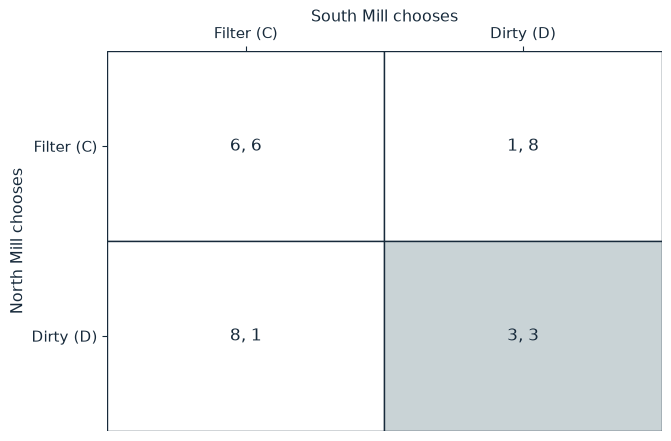

Dominance                      Dirty strictly dominates
Nash equilibria                (D, D)
Total at (C, C)                12
Total at the equilibrium       6
Gain from defecting at (C, C)  2

Worked steps:
  1. Against a filtering rival: Filter 6, Dirty 8 - 0 = 8
  2. Against a dirty rival: Filter 1, Dirty 3 - 0 = 3
  3. Equilibria: (D, D)

Against a filtering rival: Filter 6, Dirty 8 - 0 = 8; Against a dirty rival: Filter 1, Dirty 3 - 0 = 3. So Dirty strictly dominates. The unique equilibrium is (D, D). Defecting from (C, C) gains 8 - 0 - 6 = 2.


In [2]:
show(dilemma_picture(f=0))

Change one input, `f`, and hold the others at the book's values:

In [3]:
sweep(dilemma_picture, 'f', [0, 1, 2, 3], {}, ['Dominance', 'Nash equilibria'])

f | Dominance | Nash equilibria
0 | Dirty strictly dominates | (D, D)
1 | Dirty strictly dominates | (D, D)
2 | neither action dominates: each mill is indifferent against both rival actions | (C, C), (C, D), (D, C) and (D, D)
3 | Filter strictly dominates | (C, C)


Without a charge both mills run dirty and earn 3 each instead of 6. At a charge of 2 they are indifferent; at 3 filtering strictly dominates.

## 2. Volunteer's dilemma: who clears the drain?

$$p^*=1-\left(\frac{30}{120}\right)^{1/3}=1-0.25^{1/3}\approx0.370, \qquad (1-p^*)^4\approx0.157$$

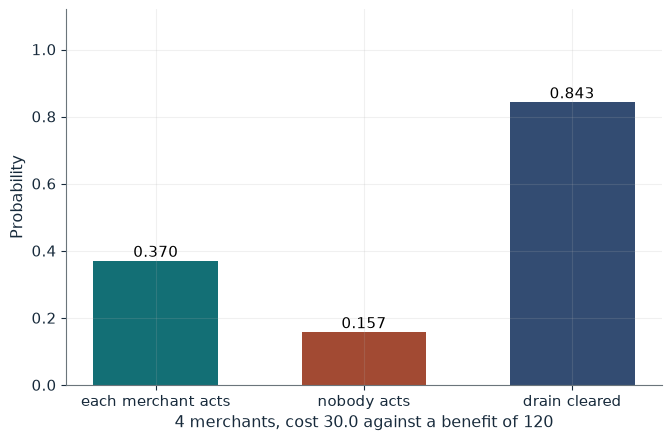

Each acts with p*     0.370
Nobody acts           0.157
Drain cleared         84.3%
Expected volunteers   1.48
Expected payoff each  90.0

Worked steps:
  1. p* = 1 - 0.2500^(1/3) = 0.370
  2. Failure = (1 - p*)^4 = 0.157
  3. Volunteers = 4 x 0.370 = 1.48
  4. Payoff = 120 - 30.0 = 90.0

p* = 1 - (30.0 / 120)^(1/3) = 1 - 0.2500^(1/3) = 0.370. Nobody acts with probability (1 - 0.370)^4 = 0.157, so the drain is cleared 84.3% of the time. Expected volunteers 4 x 0.370 = 1.48; each merchant expects 120 - 30.0 = 90.0.


In [4]:
show(volunteer_picture(n=4, cost=30))

Change one input, `n`, and hold the others at the book's values:

In [5]:
sweep(volunteer_picture, 'n', [2, 4, 6], {'cost': 30}, ['Each acts with p*', 'Nobody acts', 'Drain cleared'])

n | Each acts with p* | Nobody acts | Drain cleared
2 | 0.750 | 0.062 | 93.8%
4 | 0.370 | 0.157 | 84.3%
6 | 0.242 | 0.189 | 81.1%


With four merchants nobody acts 15.7 percent of the time. More merchants make failure more likely; a reimbursement that cuts the cost to 7.5 drops it to 0.025.

## 3. Finite-horizon unraveling

$$V_C=\frac{4}{1-0.8}=20, \qquad V_D=6+\frac{0.8(1)}{1-0.8}=10$$

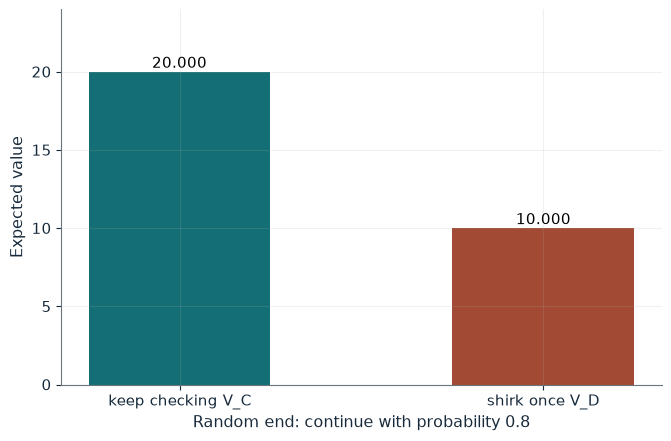

V_C                                 20.000
V_D                                 10.000
Checking sustained                  yes
Threshold continuation probability  0.40

Worked steps:
  1. V_C = 4 / 0.2 = 20.000
  2. V_D = 6 + 4.000 = 10.000
  3. Threshold = 2 / 5 = 0.40

V_C = 4 / (1 - 0.8) = 20.000. V_D = 6 + 0.8 x 1 / (1 - 0.8) = 6 + 4.000 = 10.000. So checking is sustained. Checking needs q of at least (6 - 4) / (6 - 1) = 0.40.


In [6]:
show(horizon_picture(horizon='random', q=0.8))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(horizon_picture, 'q', [0.3, 0.4, 0.8], {'horizon': 'random'}, ['V_C', 'V_D', 'Checking sustained'])

q | V_C | V_D | Checking sustained
0.3 | 5.714 | 6.429 | no
0.4 | 6.667 | 6.667 | tie (indifferent)
0.8 | 20.000 | 10.000 | yes


With three known deliveries both shirk throughout and earn 3 instead of 12. With a random end and q = 0.8 checking is worth 20 against 10; it holds for q of at least 0.4.

## 4. Trigger-strategy enforcement: punishment length

$$\delta\geq\frac{10-6}{10-2}=0.5, \qquad 10+0.75(2)+0.75^2(2)+0.75^3\left(\frac{6}{1-0.75}\right)=22.75$$

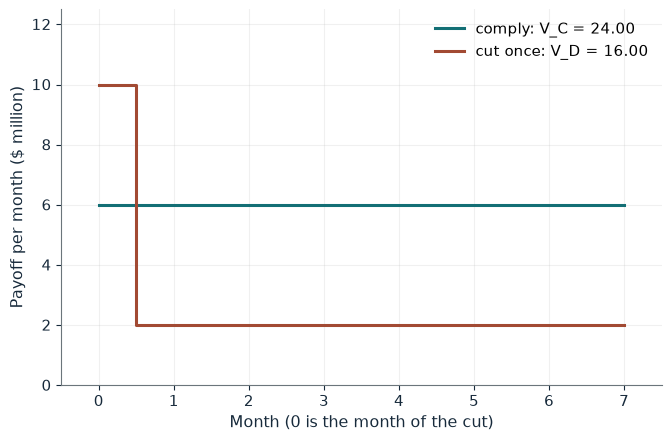

V_C                     24.00
V_D                     16.00
Punishment              permanent (grim)
Deterred                yes
Grim-trigger threshold  0.50

Worked steps:
  1. V_C = 6 / 0.25 = 24.00
  2. V_D = 10 + 0.75 x 2 / (1 - 0.75) = 10 + 6.00 = 16.00
  3. Margin = 24.00 - 16.00 = 8.00

Compliance is worth 6 / (1 - 0.75) = 24.00. With a permanent (grim) punishment, V_D = 10 + 0.75 x 2 / (1 - 0.75) = 10 + 6.00 = 16.00. So deviation is deterred. Under grim trigger cooperation needs delta of at least (10 - 6) / (10 - 2) = 0.50.


In [8]:
show(punishment_picture(delta=0.75, k='grim'))

Change one input, `k`, and hold the others at the book's values:

In [9]:
sweep(punishment_picture, 'k', ['1', '2', 'grim'], {'delta': 0.75}, ['V_C', 'V_D', 'Deterred'])

k | V_C | V_D | Deterred
1 | 24.00 | 25.00 | no
2 | 24.000 | 22.750 | yes
grim | 24.00 | 16.00 | yes


At delta 0.75 compliance is worth 24. Grim punishment gives 16 and two months 22.75, both deterring; one month gives 25 and fails.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

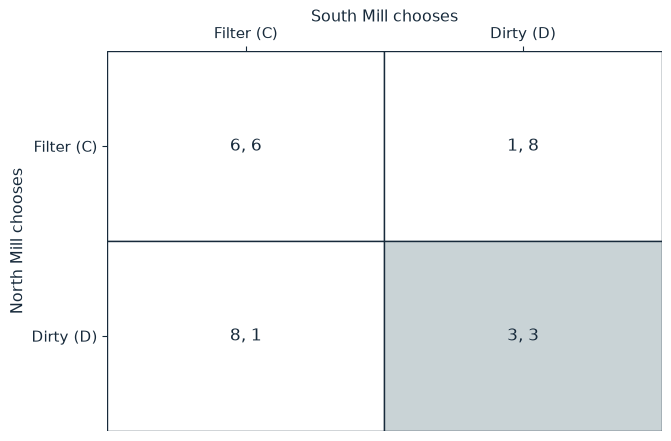

Dominance                      Dirty strictly dominates
Nash equilibria                (D, D)
Total at (C, C)                12
Total at the equilibrium       6
Gain from defecting at (C, C)  2

Worked steps:
  1. Against a filtering rival: Filter 6, Dirty 8 - 0 = 8
  2. Against a dirty rival: Filter 1, Dirty 3 - 0 = 3
  3. Equilibria: (D, D)

Against a filtering rival: Filter 6, Dirty 8 - 0 = 8; Against a dirty rival: Filter 1, Dirty 3 - 0 = 3. So Dirty strictly dominates. The unique equilibrium is (D, D). Defecting from (C, C) gains 8 - 0 - 6 = 2.


In [10]:
show(dilemma_picture(f=0))

## Practice

**1.** With a charge of 2, what are the equilibria?

<details><summary>Answer</summary>

Each mill is indifferent, so all four profiles are equilibria.

</details>

**2.** With 6 merchants and cost 30, what is the failure probability?

<details><summary>Answer</summary>

p = 0.242; failure 0.758^6 = 0.189.

</details>

**3.** At delta 0.9 with a two-month punishment, how do V_C and V_D compare?

<details><summary>Answer</summary>

V_C = 60; V_D = 10 + 1.8 + 1.62 + 43.74 = 57.16, so deviation is deterred.

</details>